# Intelligent Music Recommendation Engine

This notebook develops the recommendation engine in four phases:

1. Phase 1 — **EDA & preprocessing**: understand the long-tail data, measure sparsity, and prepare reliable modelling tables.
2. Phase 2 — **model development**: compare popularity, KNN, SVD, Co-Clustering, and an ensemble.
3. Phase 3 — **evaluation**: measure RMSE, Precision, Recall, F1, ROC curves, and AUC.
4. Phase 4 — **solution design**: compare latency and accuracy, then define deployment and cold-start strategies.

In [1]:
# imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from scipy.sparse import csr_matrix

In [2]:
# params
RANDOM_STATE = 0
# if a song or user doesnt respect both, it is a "new user" or "new song" and will be filtered out of the training set
MIN_UNIQUE = 10 # minimum n of unique users for a song, or unique songs for a user
MIN_TOTAL = 20 # minimum n of total listenings to a song, or by a user
MIN_AS_LIKE = 3 # minimum 3 times played interaction is counted as likes the song

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(RANDOM_STATE)

## 1. EDA & Preprocessing

First we verify paths.

In [3]:
DATA_DIR = Path("data")
COUNT_PATH = DATA_DIR / "count_data 3(in).csv"
SONG_PATH = DATA_DIR / "song_data 3(in).csv"
assert COUNT_PATH.exists(), f"Interaction file not found: {COUNT_PATH}"
assert SONG_PATH.exists(), f"Song metadata file not found: {SONG_PATH}"
print(f"Reading data from: {DATA_DIR.resolve()}")

Reading data from: /Users/louiedaans/Desktop/music/data


Now we can load the datasets.

In [4]:
def has_name(col):
    if col is None:
        return False
    col_str = str(col).strip()
    # keeping only columns that are not empty and don't start with 'Unnamed'
    return bool(col_str) and not col_str.startswith('Unnamed')

interactions_raw = pd.read_csv(COUNT_PATH, usecols=has_name)
songs_raw = pd.read_csv(SONG_PATH, usecols=has_name)

print("Interactions shape:", interactions_raw.shape)
print("Songs shape:", songs_raw.shape)
display(interactions_raw.head())
display(songs_raw.head())

Interactions shape: (1048575, 3)
Songs shape: (1000000, 5)


,user_id,song_id,play_count
0,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOAKIMP12A8C130995,1
1,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBBMDR12A8C13253B,2
2,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBXHDL12A81C204C0,1
3,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SOBYHAJ12A6701BF1D,1
4,b80344d063b5ccb3212f76538f3d9e43d87dca9e,SODACBL12A8C13C273,1


,song_id,title,release,artist_name,year
0,SOQMMHC12AB0180CB8,Silent Night,Monster Ballads X-Mas,Faster Pussy cat,2003
1,SOVFVAK12A8C1350D9,Tanssi vaan,Karkuteillä,Karkkiautomaatti,1995
2,SOGTUKN12AB017F4F1,No One Could Ever,Butter,Hudson Mohawke,2006
3,SOBNYVR12A8C13558C,Si Vos Querés,De Culo,Yerba Brava,2003
4,SOHSBXH12A8C13B0DF,Tangle Of Aspens,Rene Ablaze Presents Winter Sessions,Der Mystic,0


Ok, so with a first glence at the two dataset heads, we can clearly understand that they are connected by song_id.\
"Songs" table shouldn't have any duplicates on song_id.\
For "Interactions", it is normal to have duplicate id's, but in theory each interaction should be unique row (can be done multiple times using play count).\
\
Let's first handle missing values, then duplicates.

### 1.1 Missing Values

In [5]:
# for user_id let's turn " " or "" or None or any string that contains a MAJ letter into NaN
interactions_raw["user_id"] = interactions_raw["user_id"].apply(lambda x: x if isinstance(x, str) and x.islower() else pd.NA)
# for song_id let's turn " " or "" or None or any string that contains a minor letter into NaN
interactions_raw["song_id"] = interactions_raw["song_id"].apply(lambda x: x if isinstance(x, str) and x.isupper() else pd.NA)
interactions_raw["play_count"] = pd.to_numeric(interactions_raw["play_count"], errors="raise") # 0 is not considered as missing value here


# same for song_id
songs_raw["song_id"] = songs_raw["song_id"].apply(lambda x: x if isinstance(x, str) and x.isupper() else pd.NA)
# for title, release or artist_name we don't really mind about it being empty
songs_raw["year"] = pd.to_numeric(songs_raw["year"], errors="coerce").replace(0, pd.NA) # 0 is considered as missing value here so we turn it into NaN
# year should also be a 4 digit number, so we can filter out any year that is not 4 digits
songs_raw["year"] = songs_raw["year"].apply(lambda x: x if pd.isna(x) or (isinstance(x, (int, float)) and 1000 <= x <= 9999) else pd.NA)

print("Interactions missing values:")
display(interactions_raw.isna().sum().to_frame("missing_values"))
print("Songs missing values:")
display(songs_raw.isna().sum().to_frame("missing_values"))

Interactions missing values:


,missing_values
user_id,0
song_id,0
play_count,0


Songs missing values:


,missing_values
song_id,0
title,17
release,7
artist_name,0
year,484424


We can simply remove the few title and release rows since very small number.

In [6]:
# remove rows where title or release is missing
songs_raw = songs_raw.dropna(subset=["title", "release"])
print(f"Dataset shape after removing rows with missing title or release: {songs_raw.shape}")

Dataset shape after removing rows with missing title or release: (999976, 5)


A lot of empty years, that's annoying. Perhaps we can try to use duplicate release + artist_name to impute year?

In [7]:
def clean_string(val):
    if pd.isna(val):
        return ""
    return re.sub(r'[^a-z0-9]', '', str(val).lower())

songs_raw["match_key"] = (
    songs_raw["release"].apply(clean_string) + 
    songs_raw["artist_name"].apply(clean_string)
)

mixed_groups_mask = songs_raw.groupby("match_key")["year"].transform(
    lambda x: x.notna().any() and x.isna().any()
)

print("Duplicate match keys:", songs_raw.duplicated("match_key").sum())
print("Number of match_keys that have at least one non empty year and at least one empty year together:", mixed_groups_mask.sum())
print("-")
print("Total imputable rows (with empty year) in those mixed groups:", songs_raw[mixed_groups_mask & songs_raw["year"].isna()].shape[0], 
      "out of", songs_raw[songs_raw["year"].isna()].shape[0])

songs_raw[mixed_groups_mask].sort_values("match_key").head(10)

Duplicate match keys: 770408
Number of match_keys that have at least one non empty year and at least one empty year together: 206411
-
Total imputable rows (with empty year) in those mixed groups: 106217 out of 484404


,song_id,title,release,artist_name,year,match_key
69910,SOKFUQW12A8AE4807C,Jesus In the Year 2000 / Next on the Shit List,012:2,Coalesce,1999,0122coalesce
119992,SOFHTGT12A8AE4809A,They Always Come In Fall,012:2,Coalesce,1999,0122coalesce
274077,SOZJPTZ12A8AE48090,Counting Murders and Drinking Beer (The $46_00...,012:2,Coalesce,<NA>,0122coalesce
30544,SODOKUC12A8AE48076,Where the Hell Is Rick Thorne These Days?,012:2,Coalesce,1999,0122coalesce
296039,SOODHBH12A8AE4806C,Burn Everything That Bears Our Name,012:2,Coalesce,1999,0122coalesce
890912,SOZQKTN12A58A7C146,Sometimes Selling Out Is Waking Up,012:2,Coalesce,1999,0122coalesce
117775,SOIYPCZ12AF729D6FD,While the Jackass Operation Spins Its Wheels,012:2,Coalesce,1999,0122coalesce
273886,SOIBNGS12AF72A2E7D,What Happens on the Road Always Comes Home,012:2,Coalesce,1999,0122coalesce
866569,SOVJVSG12A8C13EE3C,- kumo - (Live),020120 (Live),The Mad Capsule Markets,<NA>,020120livethemadcapsulemarkets
598862,SOBPJCE12A8C13EE42,No Food_ Drink_ Or Smoking (Live),020120 (Live),The Mad Capsule Markets,<NA>,020120livethemadcapsulemarkets


Not too bad, let's impute.

In [8]:
release_years = songs_raw.dropna(subset=["year"]).groupby("match_key")["year"].first()
songs_raw["year"] = songs_raw["year"].fillna(songs_raw["match_key"].map(release_years))

print(f"Remaining missing years: {songs_raw['year'].isna().sum()}")
print(f"Remaining missing years per match_key: {songs_raw[songs_raw['year'].isna()]['match_key'].nunique()}")

Remaining missing years: 378187
Remaining missing years per match_key: 109839


A lot of empty year values are still left. We could perhaps try to impute all the rest with a median of year of releases from the same artist, but I don't like that option so much since it could remove the actual potential value "year" brings to the recommender system.\
\
For the moment we can leave it like this. We will still later on have to figure out if there is a stastical trend in liked songs and year etc so let's just keep it as it is.

### 1.2 Duplicates

Ok, empty values are controlled, now let's move on to duplicates. As said before we don't want duplicate song_id's in "songs".

In [9]:
duplicate_songs = songs_raw[songs_raw.duplicated("song_id", keep=False)].sort_values("song_id")
print("Duplicate song IDs ", duplicate_songs.shape[0], "rows")

# show some examples of duplicate song IDs
display(duplicate_songs.head(10))

Duplicate song IDs  1840 rows


,song_id,title,release,artist_name,year,match_key
963681,SOAAEFC12AB01852F1,De Tongbreker,Alle 40 Goed - Hollandse Duetten,Tineke Schouten/Linda De Mol/Franklin Brown,NaN,alle40goedhollandseduettentinekeschoutenlindad...
304966,SOAAEFC12AB01852F1,De Tongbreker (Tineke Schouten & Linda de Mol),16 Liedjes Uit De Tineke Schouten Shows,Tineke Schouten,NaN,16liedjesuitdetinekeschoutenshowstinekeschouten
572832,SOACGAQ12A58A79805,Fire And The Thud,Humbug,Arctic Monkeys,2009,humbugarcticmonkeys
141269,SOACGAQ12A58A79805,Fire And The Thud,Humbug,Arctic Monkeys,2009,humbugarcticmonkeys
15028,SOADFGH12A6D4F74F7,Falling Into Grace (Album Version),One Hot Minute,Red Hot Chili Peppers,1995,onehotminuteredhotchilipeppers
522461,SOADFGH12A6D4F74F7,Falling Into Grace (Album Version),One Hot Minute,Red Hot Chili Peppers,1995,onehotminuteredhotchilipeppers
68224,SOADYVX12A8A9D9462,We Ride,We Ride,Rihanna,2006,weriderihanna
655219,SOADYVX12A8A9D9462,We Ride,We Ride,Rihanna,2006,weriderihanna
182693,SOAEIFW12A8C1391E4,Michael,Michael,Franz Ferdinand,2004,michaelfranzferdinand
525920,SOAEIFW12A8C1391E4,Michael,Michael,Franz Ferdinand,2004,michaelfranzferdinand


For each duplicate\
To decide which one we keep, we remove from our candidates the ones that don't have a valid year. (remove no candidates if they all empty year)\
Then from the ones left, we take the one that has the match_key with the most duplicates (if all the same, take first)

In [10]:
n_before = songs_raw.shape[0]

# calc n dups of match_key
match_key_counts = songs_raw["match_key"].value_counts()
songs_raw["match_key_freq"] = songs_raw["match_key"].map(match_key_counts).fillna(0)

# boolean flag for valid year or not
songs_raw["has_year"] = songs_raw["year"].notna()

songs_raw = songs_raw.sort_values(
    by=["has_year", "match_key_freq"], 
    ascending=[False, False], 
    kind="mergesort"
)

songs_raw = songs_raw.drop_duplicates(subset=["song_id"], keep="first")
songs_raw = songs_raw.drop(columns=["has_year", "match_key_freq"])
print(f"Removed {n_before - songs_raw.shape[0]} duplicate song IDs")

Removed 944 duplicate song IDs


Ok, now we also need to make sure the interaction pairs are unique.

In [11]:
# check how many duplicate interaction pairs we have
print("Duplicate interaction pairs:", interactions_raw.duplicated(["user_id", "song_id"]).sum())
print("Non-positive play counts:", (interactions_raw["play_count"] <= 0).sum())

Duplicate interaction pairs: 0
Non-positive play counts: 0


Well, good news.

In [12]:
# check how many total users
print("Total users:", interactions_raw["user_id"].nunique())
# check how many total songs
print("Total songs:", interactions_raw["song_id"].nunique())
# check if all song_ids in interactions are present in songs
missing_song_ids = set(interactions_raw["song_id"].unique()) - set(songs_raw["song_id"].unique())
print("Missing song IDs in songs metadata:", len(missing_song_ids))
# how many song are in songs but not in interactions
missing_song_ids_in_interactions = set(songs_raw["song_id"].unique()) - set(interactions_raw["song_id"].unique())
print("Missing song IDs in interactions:", len(missing_song_ids_in_interactions))
# how many song ids from songs are in use in interactions
used_song_ids = set(interactions_raw["song_id"].unique())
print("Used song IDs in interactions:", len(used_song_ids))

Total users: 40336
Total songs: 10000
Missing song IDs in songs metadata: 0
Missing song IDs in interactions: 989032
Used song IDs in interactions: 10000


Unfortunate, only 10k out of 1M are actually used in interactions. Perhaps we could say the streaming platform we are building a recommendation system for is very fresh and new, and a lot of song haven't been played yet. We will thus remove surplus for our statistical models, but we keep them as recomendations for new users perhaps, since the platform wants to promote unheard music perhaps? We will see later what we do with the rest of the songs, but logically they will enter the interactions sooner or later so let's focus on interaction only first.

In [13]:
songs = songs_raw[songs_raw["song_id"].isin(used_song_ids)].copy()
interactions = interactions_raw[interactions_raw["song_id"].isin(used_song_ids)].copy() # should be fine as we seen above, should still be 1_048_575
print(f"Filtered songs metadata shape: {songs.shape}")
print(f"Filtered interactions shape: {interactions.shape}")

Filtered songs metadata shape: (10000, 6)
Filtered interactions shape: (1048575, 3)


### 1.3 Distributions

,unique_songs,total_play_count,average_play_count,max_play_count
count,40336.00,40336.00,40336.00,40336.00
mean,26.00,79.20,3.21,13.48
std,31.26,114.57,3.82,21.85
min,1.00,1.00,1.00,1.00
25%,9.00,17.00,1.42,3.00
50%,16.00,41.00,2.17,7.00
75%,31.00,94.00,3.60,15.00
max,711.00,3482.00,192.00,920.00


,unique_songs,total_play_count,average_play_count,max_play_count
user_id,,,,
6d625c6557df84b60d90426c0116138b617b9449,711,3482,4.897328,225
283882c3d18ff2ad0e17124002ec02b847d06e9a,309,2306,7.462783,95
083a2a59603a605275107c00812a811526c2a0af,104,2142,20.596154,206
6a944bfe30ae8d6b873139e8305ae131f1607d5f,452,2062,4.561947,271
9c859962257112ad523f1d3c121d35191daa6d2b,473,2032,4.295983,49
2231cb435771a1a621ec44e95cdd28b81fad3288,56,2019,36.053571,182
dc02d3c4fb534ca1406f720c70678e5858a5ca0a,89,1856,20.853933,96
6ccd111af9b4baa497aacd6d1863cbf5a141acc6,140,1832,13.085714,215
0091e0326c4c034cc04be6454742912845740a1f,78,1499,19.217949,115


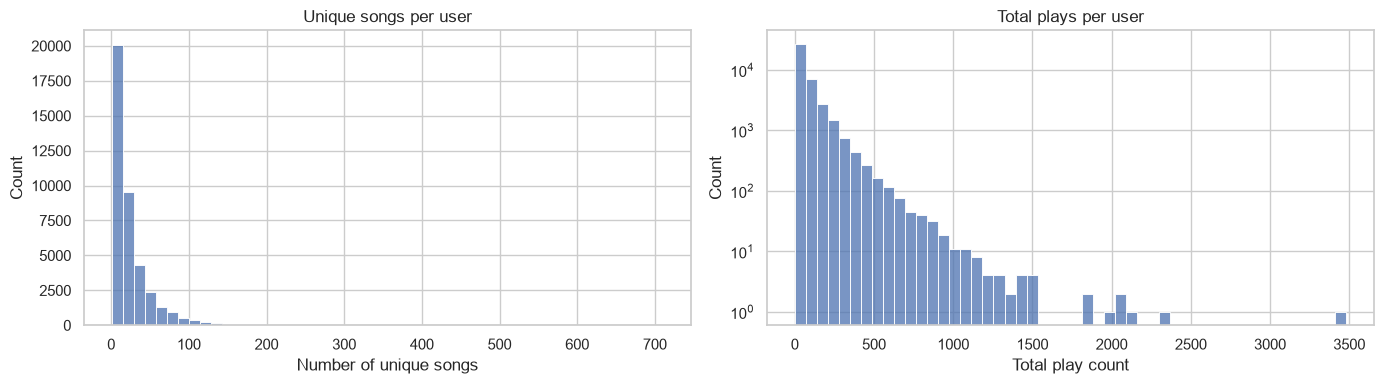

In [14]:
user_summary = (
    interactions.groupby("user_id")
    .agg(
        unique_songs=("song_id", "nunique"), # number of unique songs listened to by user
        total_play_count=("play_count", "sum"), # total play count of user
        average_play_count=("play_count", "mean"), # average play count per song
        max_play_count=("play_count", "max") # max play count of a song (most listened song) for the user
    )
    .sort_values("total_play_count", ascending=False)
)

display(user_summary.describe().round(2))
display(user_summary.head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(user_summary["unique_songs"], bins=50, ax=axes[0])
axes[0].set_title("Unique songs per user")
axes[0].set_xlabel("Number of unique songs")
sns.histplot(user_summary["total_play_count"], bins=50, ax=axes[1])
axes[1].set_title("Total plays per user")
axes[1].set_xlabel("Total play count")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

Personally, I have over 2000 unique liked songs on my spotify, that's also what I expected from an average user here, but no.\
\
We observe a classic **long-tail (power-law) distribution** across two key user dimensions:

* **Unique songs per user:** The vast majority of users interact with a very small subset of tracks, heavily concentrated between 0 and 25 unique songs.
* **Total plays per user:** Plotted on a logarithmic scale, total activity is similarly skewed. Most users have low overall play counts.

Impact on Potential Model Bias:

1. **Popularity Bias:** 
   Because interaction data is heavily concentrated around a small group of popular items, collaborative filtering models will naturally develop a strong **popularity bias**. The model optimizes for safer, high-frequency "head" items to minimize loss, often starving the long-tail of niche songs and failing to surface diverse recommendations.

2. **Sparsity:** 
   The massive spike of users with very few unique song interactions creates a severe sparsity problem. The model will struggle to find meaningful neighbor patterns or similarities for these casual listeners, which can lead to generic, non-personalized recommendations for the majority of the user base.

3. **Power-User Dominance:** 
   With total play counts stretching past 3,500 for heavy listeners, unweighted loss functions risk being disproportionately influenced by the preference patterns of a few power users, overriding the signal of typical, casual listeners.

,unique_users,total_play_count,average_play_count,max_play_count
count,10000.00,10000.00,10000.00,10000.00
mean,104.86,319.45,2.86,30.54
std,166.03,726.76,1.39,36.19
min,19.00,29.00,1.02,2.00
25%,47.00,112.00,2.00,12.00
50%,65.00,177.00,2.56,20.50
75%,105.00,312.00,3.32,36.00
max,4368.00,28101.00,33.43,920.00


,unique_users,total_play_count,average_play_count,max_play_count
song_id,,,,
SOBONKR12A58A7A7E0,3336,28101,8.423561,446
SOAUWYT12A81C206F1,3693,24632,6.669916,219
SOSXLTC12AF72A7F54,3179,21278,6.693300,488
SOEGIYH12A6D4FC0E3,2830,16277,5.751590,179
SOFRQTD12A81C233C0,4368,15813,3.620192,70
SOAXGDH12A8C13F8A1,3676,14031,3.816921,82
SONYKOW12AB01849C9,3051,11524,3.777122,144
SOPUCYA12A8C13A694,1794,11099,6.186734,236
SOUFTBI12AB0183F65,1521,10569,6.948718,272


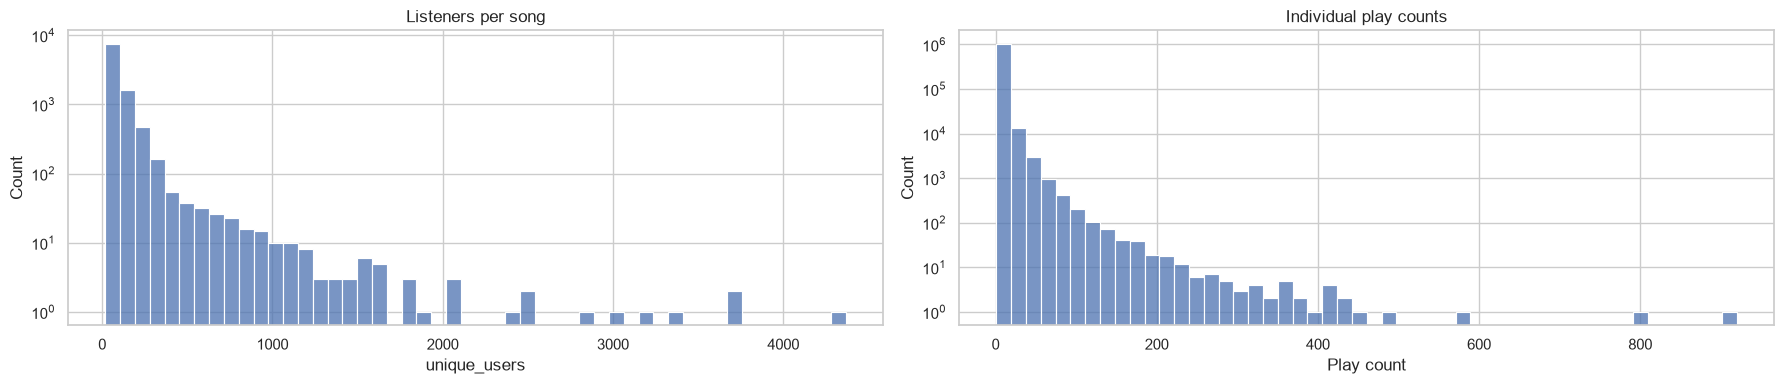

In [15]:
song_summary = (
    interactions.groupby("song_id")
    .agg(
        unique_users=("user_id", "nunique"), # number of unique users that listened to the song
        total_play_count=("play_count", "sum"), # total play count of the song
        average_play_count=("play_count", "mean"), # average play count per user
        max_play_count=("play_count", "max") # max play count of a user (most listened user) for the song
    )
    .sort_values("total_play_count", ascending=False)
)

display(song_summary.describe().round(2))
display(song_summary.head(20))

ranked_songs = song_summary.reset_index()
ranked_songs["rank"] = np.arange(1, len(ranked_songs) + 1)
fig, axes = plt.subplots(1, 2, figsize=(18, 4))
sns.histplot(song_summary["unique_users"], bins=50, ax=axes[0])
axes[0].set_title("Listeners per song")
axes[0].set_yscale("log")
sns.histplot(interactions["play_count"], bins=50, ax=axes[1])
axes[1].set_title("Individual play counts")
axes[1].set_yscale("log")
axes[1].set_xlabel("Play count")
plt.tight_layout()
plt.show()

Same tendencies on the song side.

In [16]:
play_count_summary = interactions["play_count"].describe(percentiles=[0.50, 0.90, 0.95, 0.99, 0.999])
display(play_count_summary.to_frame("play_count").round(2))

,play_count
count,1048575.00
mean,3.05
std,6.37
min,1.00
50%,1.00
90%,6.00
95%,10.00
99%,26.00
99.9%,72.00
max,920.00


Here we can visualise the skewness in another more simple way. The median is of 1. Then we have this huge gap between 99% and max, while the gap between min and 95 for example is pretty low.

### 1.4 Sparsity Reduction

First we can create a sparse user-song matrix where rows are users, columns are songs, and values are play_count.

In [17]:
def make_sparse_matrix(interactions):
    user_codes = interactions["user_id"].astype("category")
    song_codes = interactions["song_id"].astype("category")
    matrix = csr_matrix((interactions["play_count"],(user_codes.cat.codes, song_codes.cat.codes)))
    return matrix

sparse_matrix = make_sparse_matrix(interactions)
density = sparse_matrix.nnz / (sparse_matrix.shape[0] * sparse_matrix.shape[1])

print("Matrix shape:", sparse_matrix.shape)
print("Stored interactions:", sparse_matrix.nnz)
print(f"Density: {density:.4%}")
print(f"Sparsity: {1 - density:.4%}")

Matrix shape: (40336, 10000)
Stored interactions: 1048575
Density: 0.2600%
Sparsity: 99.7400%


So, here I had to think for a bit. My first thought was "we can't just aggressively filter users that have listened to fewer than N songs, or songs that have fewer than M listenings". I thought of other ways to do it, keeping more data, using for example Alternating Least Squares method. But when thinking about the final predictions we need to make, the final models we want to compare, we are better to separate our users and songs into 4 groups:

- new users
- users
- new songs
- songs
  
New users become users only when they have at least listened to N songs with and a minimum total listening count of M.\
New songs become songs only when they have at least been listened to M times, by at least N unique users.\
\
Why N=10 and M=20? Not sure yet, I will try to optimise this later during modeling phases.

In [18]:
# we use iterative k-core filtering to ensure that all conditions are respected
def filter_k_core(interactions, min_unique=MIN_UNIQUE, min_total=MIN_TOTAL, min_as_like=MIN_AS_LIKE):
    while True:
        # filter min unique songs per user
        user_counts = interactions.groupby("user_id").size()
        valid_users = user_counts[user_counts >= min_unique].index
        interactions = interactions[interactions["user_id"].isin(valid_users)]

        # filter min unique listeners per song
        song_counts = interactions.groupby("song_id").size()
        valid_songs = song_counts[song_counts >= min_unique].index
        interactions = interactions[interactions["song_id"].isin(valid_songs)]

        # filter total listenings users
        total_listenings = interactions.groupby("user_id")["play_count"].sum()
        valid_users_total = total_listenings[total_listenings >= min_total].index
        interactions = interactions[interactions["user_id"].isin(valid_users_total)]

        # filter total listenings songs
        total_listenings_song = interactions.groupby("song_id")["play_count"].sum()
        valid_songs_total = total_listenings_song[total_listenings_song >= min_total].index
        interactions = interactions[interactions["song_id"].isin(valid_songs_total)]

        # then we want to keep only users that have at least 3 songs that they have listened to at least min_as_like times
        # so that one can be used as a training example and one as a test example for the user
        # or one for train/test and two for context of other song liked
        user_song_counts = interactions.groupby(["user_id", "song_id"])["play_count"].sum()
        valid_users_as_like = user_song_counts[user_song_counts >= min_as_like].groupby("user_id").size()
        valid_users_as_like = valid_users_as_like[valid_users_as_like >= 3].index
        interactions = interactions[interactions["user_id"].isin(valid_users_as_like)]

        if (len(valid_users) == len(user_counts)) and (len(valid_songs) == len(song_counts)):
            break # if no changes break loop

    return interactions

# go and filter
interactions_filtered = filter_k_core(interactions)
print(f"With params: MIN_UNIQUE={MIN_UNIQUE}, MIN_TOTAL={MIN_TOTAL}")
print(f"Went from {interactions.shape[0]} interactions to {interactions_filtered.shape[0]} after k-core filtering")
print(f"Went from {interactions['user_id'].nunique()} users to {interactions_filtered['user_id'].nunique()} after k-core filtering")
print(f"Went from {interactions['song_id'].nunique()} songs to {interactions_filtered['song_id'].nunique()} after k-core filtering")

With params: MIN_UNIQUE=10, MIN_TOTAL=20
Went from 1048575 interactions to 827100 after k-core filtering
Went from 40336 users to 21389 after k-core filtering
Went from 10000 songs to 9998 after k-core filtering


In [19]:
filtered_sparse_matrix = make_sparse_matrix(interactions_filtered)
filtered_density = filtered_sparse_matrix.nnz / (filtered_sparse_matrix.shape[0] * filtered_sparse_matrix.shape[1])

print("Filtered matrix shape:", filtered_sparse_matrix.shape)
print("Filtered stored interactions:", filtered_sparse_matrix.nnz)
print(f"Filtered density: {filtered_density:.4%}")
print(f"Filtered sparsity: {1 - filtered_density:.4%}")

Filtered matrix shape: (21389, 9998)
Filtered stored interactions: 827100
Filtered density: 0.3868%
Filtered sparsity: 99.6132%


It reduces sparsity by a little little bit, but forcing to end up with very few data isn't the best option either. Later we will parameter tune using different MAX_UNIQUE and MAX_TOTAL values.

Perhaps it can be a good idea for some models to use log scales etc, but let's try that out directly during modeling phase, for now we just have to accept how the data is distributed, it is realistic.

### 1.5 Outliers

,median,q1,q3,minimum,maximum,outliers
Unique songs per user,27.0,16.0,46.0,9,711,106
Total plays per user,86.0,51.0,157.0,20,3482,107
Unique users per song,51.0,37.0,84.0,14,3360,50
Total plays per song,151.0,94.0,269.0,21,24995,50
Plays per interaction,1.0,1.0,3.0,1,796,3962


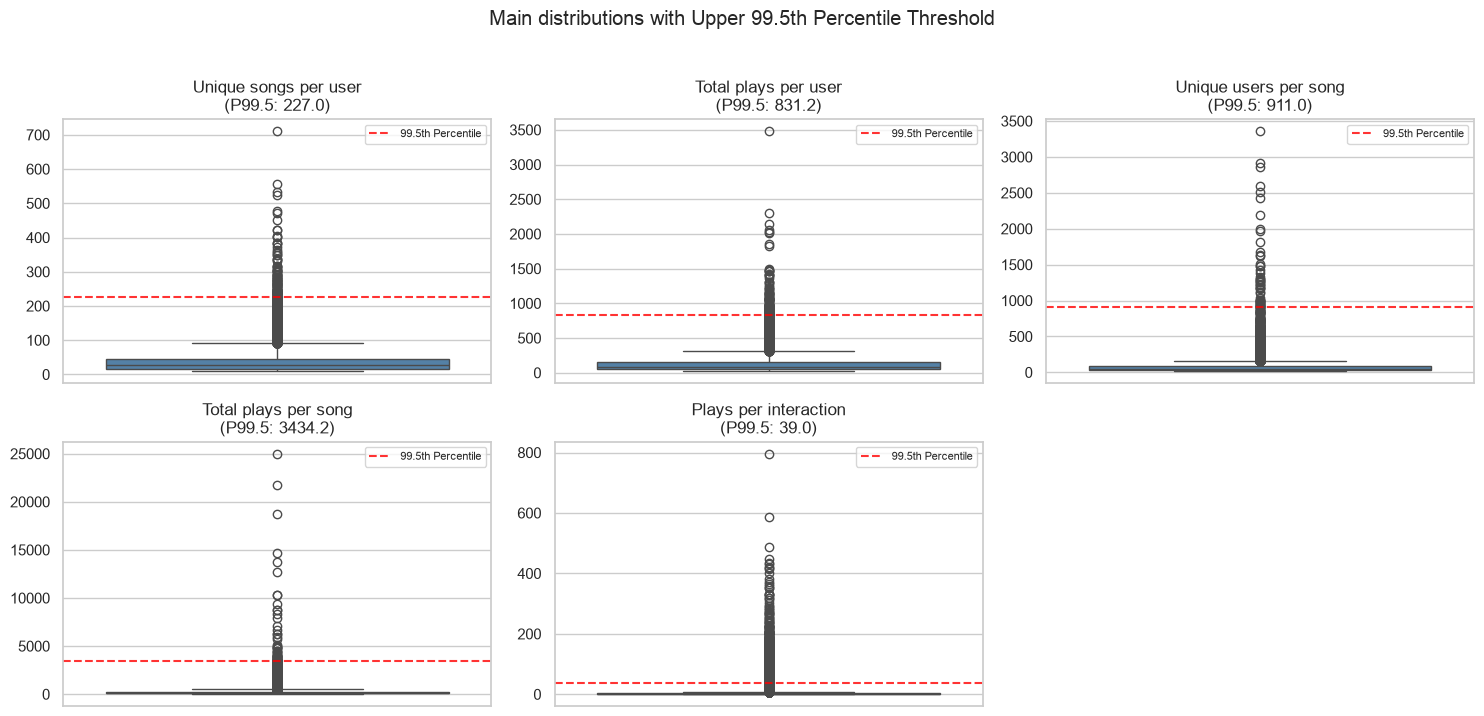

In [20]:
# Key distributions and IQR outlier counts
def outlier_count(series):
    threshold = series.quantile(0.995)
    return (series > threshold).sum()

user_summary = (
    interactions_filtered.groupby("user_id")
    .agg(
        unique_songs=("song_id", "nunique"),
        total_play_count=("play_count", "sum"),
        average_play_count=("play_count", "mean"),
        max_play_count=("play_count", "max")
    ))

song_summary = (
    interactions_filtered.groupby("song_id")
    .agg(
        unique_users=("user_id", "nunique"),
        total_play_count=("play_count", "sum"),
        average_play_count=("play_count", "mean"),
        max_play_count=("play_count", "max")
    ))

outlier_data = {
    "Unique songs per user": user_summary["unique_songs"],
    "Total plays per user": user_summary["total_play_count"],
    "Unique users per song": song_summary["unique_users"],
    "Total plays per song": song_summary["total_play_count"],
    "Plays per interaction": interactions_filtered["play_count"],
}

statistics = pd.DataFrame({
    "median": {name: values.median() for name, values in outlier_data.items()},
    "q1": {name: values.quantile(0.25) for name, values in outlier_data.items()},
    "q3": {name: values.quantile(0.75) for name, values in outlier_data.items()},
    "minimum": {name: values.min() for name, values in outlier_data.items()},
    "maximum": {name: values.max() for name, values in outlier_data.items()},
    "outliers": {name: outlier_count(values) for name, values in outlier_data.items()},
}).round(2)

display(statistics)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (name, values) in zip(axes.flat, outlier_data.items()):
    sns.boxplot(y=values, ax=ax, color="steelblue")
    
    p99_val = values.quantile(0.995)
    ax.axhline(p99_val, color="red", linestyle="--", alpha=0.8, label="99.5th Percentile")
    
    ax.set_title(f"{name}\n(P99.5: {p99_val:.1f})")
    ax.set_ylabel("")
    ax.legend(loc="upper right", fontsize=8)

axes.flat[-1].axis("off")
fig.suptitle("Main distributions with Upper 99.5th Percentile Threshold", y=1.02)
plt.tight_layout()
plt.show()

Rather than treating these extreme values as errors to be deleted, we recognize them as authentic, real-world listening habits. Because removing them would unnecessarily shrink our dataset, we prefer to keep this tail intact and handle the skewness using appropriate scaling techniques or implicit models.

Perhaps 800 plays on a single song seems off.

In [21]:
# show top 10 most listened songs of the user that has the interaction with the highest play count
top_user_id = interactions_filtered.loc[interactions_filtered["play_count"].idxmax(), "user_id"]
top_songs = interactions_filtered[interactions_filtered["user_id"] == top_user_id].groupby("song_id").sum().sort_values("play_count", ascending=False)
top_song_id = top_songs.index[0]
print(songs[songs["song_id"] == top_song_id][["title", "artist_name", "release", "year"]])
top_songs.head(5)

                    title    artist_name    release  year
601977  Paradise & Dreams  Darren Styles  Skydivin'  2008


,user_id,play_count
song_id,,
SOZQSVB12A8C13C271,bb85bb79612e5373ac714fcd4469cabeb5ed94e1,796
SOOKGRB12A8C13CD66,bb85bb79612e5373ac714fcd4469cabeb5ed94e1,16
SOUGHFP12A8C13CD5D,bb85bb79612e5373ac714fcd4469cabeb5ed94e1,15
SONSAEZ12A8C138D7A,bb85bb79612e5373ac714fcd4469cabeb5ed94e1,14
SOXMIUS12A8C13CD59,bb85bb79612e5373ac714fcd4469cabeb5ed94e1,13


In [22]:
# same but for the second highest play count interaction
second_top_user_id = interactions_filtered.loc[interactions_filtered["play_count"].nlargest(2).idxmin(), "user_id"]
second_top_songs = interactions_filtered[interactions_filtered["user_id"] == second_top_user_id].groupby("song_id").sum().sort_values("play_count", ascending=False)
second_top_song_id = second_top_songs.index[0]
print(songs[songs["song_id"] == second_top_song_id][["title", "artist_name", "release", "year"]])
second_top_songs.head(5)

            title artist_name                      release  year
577438  The Quest   HYPOCRISY  A Taste Of Extreme Divinity  2009


,user_id,play_count
song_id,,
SOZPMJT12AAF3B40D1,f1bdbb9fb7399b402a09fa124210dedf78e76034,585
SOJSXJY12A8C13E32E,f1bdbb9fb7399b402a09fa124210dedf78e76034,137
SOGXSJZ12A8AE45AAD,f1bdbb9fb7399b402a09fa124210dedf78e76034,98
SOXFYTY127E9433E7D,f1bdbb9fb7399b402a09fa124210dedf78e76034,75
SOUPIYD12A6701DD0B,f1bdbb9fb7399b402a09fa124210dedf78e76034,51


The second one looks more natural, the first one is clearly not normal, unless he is just a huge fan of that song. But in either case, that's outside of the scope of the assignement, our goal is not to make a anomaly detection system.

But what I'm going to do is capping play count at the 99.5th percentile which is around 39 from outputs.

Max play count after capping: 39
Min play count: 1


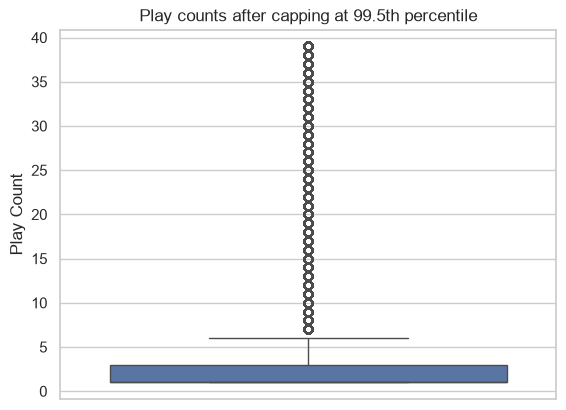

In [23]:
# cap play counts at 99.5th percentile
interactions_filtered["play_count"] = interactions_filtered["play_count"].clip(upper=interactions_filtered["play_count"].quantile(0.995))
print("Max play count after capping:", interactions_filtered["play_count"].max())
print("Min play count:", interactions_filtered["play_count"].min())

# visualise with box plot
sns.boxplot(y=interactions_filtered["play_count"])
plt.title("Play counts after capping at 99.5th percentile")
plt.ylabel("Play Count")
plt.show()


In [24]:
# perhaps we can create 3 groups/bins
# if user has 1 play -> doesn't like
# if user has 2 plays -> maybe likes
# if user has 3 or more plays -> likes
# let's try to visualise distribution in that way, it might be a bit more balanced

conditions = [
    interactions_filtered["play_count"] == 1,
    interactions_filtered["play_count"] == 2,
    interactions_filtered["play_count"] >= 3
]
strings = ["doesn't like", "maybe likes", "likes"]
interactions_filtered["like_category"] = np.select(conditions, strings, default="unknown")

like_counts = interactions_filtered["like_category"].value_counts()
print(like_counts)

like_category
doesn't like    429599
likes           263600
maybe likes     133901
Name: count, dtype: int64


Makes more sense.

#### Phase 1 conclusion
The data was cleaned and prepared for modelling. It contains many users and songs, but the interaction matrix is naturally very sparse. K-core filtering removed users with too little listening history and slightly reduced sparsity while keeping most interactions. The play counts are also highly skewed, so log transformation may be useful during modelling. The prepared data can now be used to compare different recommendation models.

## 2. Model development

### 2.1 train/(val)/test Split

So the main idea here is to split per user.
For each user we split like this:
- 1th most "liked" song for validation (liked is over 3 plays)
- 2th most "liked" song for test
- the rest of liked songs for train

The most important rule is that the test songs must not be visible during training.

Since val and test are hidden for training, if we only had 3 liked songs, we don't have any other liked songs to reference to for trying to recommend songs, so for training we only keep the candidates that have at least 5 liked songs, the rest become extra validate or test patients.

In [25]:
print(f"n_interactions: {len(interactions_filtered)}, n_users: {interactions_filtered['user_id'].nunique()}, n_songs: {interactions_filtered['song_id'].nunique()}")

# keep only liked interactions and aggregate (safe even if duplicates exist)
liked = (
    interactions_filtered[interactions_filtered["play_count"] >= MIN_AS_LIKE]
    .groupby(["user_id", "song_id"], as_index=False)["play_count"]
    .sum())

# rank songs per user by play_count (highest first)
liked = liked.sort_values(["user_id", "play_count", "song_id"], ascending=[True, False, True]).copy()
liked["rank_like"] = liked.groupby("user_id").cumcount() + 1

# decide who is eligible for full split (needs at least top 3 liked songs)
liked_count_per_user = liked.groupby("user_id")["song_id"].size()
main_users = liked_count_per_user[liked_count_per_user >= 3].index
main = liked[liked["user_id"].isin(main_users)].copy()

# main split
val_df = main[main["rank_like"] == 1].copy()
test_df = main[main["rank_like"] == 2].copy()
train_df = main[main["rank_like"] > 2].copy()

# quick checks
assert set(train_df[["user_id", "song_id"]].apply(tuple, axis=1)).isdisjoint(
    set(val_df[["user_id", "song_id"]].apply(tuple, axis=1))
)
assert set(train_df[["user_id", "song_id"]].apply(tuple, axis=1)).isdisjoint(
    set(test_df[["user_id", "song_id"]].apply(tuple, axis=1))
)
assert set(val_df[["user_id", "song_id"]].apply(tuple, axis=1)).isdisjoint(
    set(test_df[["user_id", "song_id"]].apply(tuple, axis=1))
)

print("=== Main split (users with >=3 liked songs) ===")
print("Train rows:", len(train_df), "| users:", train_df["user_id"].nunique())
print("Val rows:  ", len(val_df),   "| users:", val_df["user_id"].nunique())
print("Test rows: ", len(test_df),  "| users:", test_df["user_id"].nunique())
print("Distribution in %:", 
      f"Train: {len(train_df) / len(main) * 100:.2f}%, "
      f"Val: {len(val_df) / len(main) * 100:.2f}%, "
      f"Test: {len(test_df) / len(main) * 100:.2f}%")

n_interactions: 827100, n_users: 21389, n_songs: 9998
=== Main split (users with >=3 liked songs) ===
Train rows: 220822 | users: 21389
Val rows:   21389 | users: 21389
Test rows:  21389 | users: 21389
Distribution in %: Train: 83.77%, Val: 8.11%, Test: 8.11%


Now we can create a training matrix.

In [30]:
# using all users and songs from the main split
user_ids = sorted(main["user_id"].unique())
song_ids = sorted(main["song_id"].unique())

user_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
song_to_index = {song_id: index for index, song_id in enumerate(song_ids)}
index_to_song = {index: song_id for song_id, index in song_to_index.items()}

# only training interactions in the matrix
train_rows = train_df["user_id"].map(user_to_index).to_numpy()
train_cols = train_df["song_id"].map(song_to_index).to_numpy()

# log-transform play counts so very large values do not dominate
train_values = np.log1p(train_df["play_count"].to_numpy(dtype=float))

train_matrix = csr_matrix(
    (
        train_values,
        (train_rows, train_cols)
    ),
    shape=(len(user_ids), len(song_ids))
)

# Songs already seen by each user in training
seen_by_user = (
    train_df.groupby("user_id")["song_id"]
    .apply(set)
    .to_dict()
)

print("Sparse training matrix shape:", train_matrix.shape)
print("Stored non-zero values:", train_matrix.nnz)
print(
    "Training matrix density:",
    f"{train_matrix.nnz / (train_matrix.shape[0] * train_matrix.shape[1]):.2%}"
)

Sparse training matrix shape: (21389, 9998)
Stored non-zero values: 784322
Training matrix density: 0.37%


### 2.2 Baseline model

So here the most intuitive is to just make this popularity based. But on the other side it might also be a great way to introduce some new music too, perhaps music with some traction to it (not necessarelly the most popular). The problem is that we don't have timestamps etc so traction will be complicated to calculate.\
\
For our system we will thus only recommend new songs (max 1y old), by cutting all 1y old songs into 10 popularity bins and taking a random out of each, so that we mix popularity, traction, and innovation.

In [29]:
print(f"Max year: {songs['year'].max()}")
print(f"Amount of songs belonging to that year: {songs[songs['year'] == songs['year'].max()].shape[0]}")

Max year: 2010
Amount of songs belonging to that year: 295


Ok so our recommender is in 2010. Since we have very few songs this year, we absolutly need to recommend new songs to also attract artists to our platform.

In [38]:
def get_baseline_recommendations(train_df, songs, random_state=0):
    song_popularity = (
        train_df.groupby("song_id")
        .agg(
            unique_listeners=("user_id", "nunique"),
            total_plays=("play_count", "sum")
        ).reset_index())

    song_popularity = song_popularity.merge(
        songs[["song_id", "title", "artist_name", "year"]],
        on="song_id",
        how="left"
    )

    song_popularity["popularity_score"] = (
        song_popularity["unique_listeners"]
        + np.log1p(song_popularity["total_plays"])
    )

    max_year = songs["year"].max()

    # only from this year
    new_songs = song_popularity[
        song_popularity["year"] >= max_year
    ].copy()

    # divide songs into popularity groups
    new_songs["popularity_bin"] = pd.qcut(
        new_songs["popularity_score"],
        q=10,
        labels=False,
        duplicates="drop"
    )

    # choose one random song from each popularity group
    baseline_recommendations = (
        new_songs.groupby("popularity_bin", group_keys=False)
        .sample(n=1, random_state=random_state)
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return baseline_recommendations[["song_id", "title", "artist_name", "year"]]

baseline_rec = get_baseline_recommendations(train_df, songs, random_state=10)
display(baseline_rec)

,song_id,title,artist_name,year
0,SOTGZIH12A8C1428A5,Swim Until You Cant See Land,Frightened Rabbit,2010
1,SOJJUKR12AB018509A,Sole Nero,Litfiba,2010
2,SOYGFZL12AB018639E,Night By Night,Chromeo,2010
3,SOXEHUH12AB018D1E0,Brian Eno,MGMT,2010
4,SOQQJFK12AB018D1B5,We Could Forever,Bonobo,2010
5,SODWRNB12AB0183B3B,Entre Tus Alas,Camila,2010
6,SOOEJPA12AB018C54E,Troubles Will Be Gone,The Tallest Man On Earth,2010
7,SOINUJV12A8C1429E9,Thieves In The Night,Hot Chip,2010
8,SOOTKBQ12AC3DFA4A2,Man/Bag Of Sand,Frightened Rabbit,2010
9,SOGCWUH12AC90732B0,U Smile,Justin Bieber,2010


## Phase 3

## Phase 4